# 04. Forecasting Monthly Reported Seizure Records

## Research question

Can monthly reported seizure-record counts be forecast using simple
time-series baselines and an XGBoost regression model?

The target is the **number of records in the IDS dataset**, not drug
quantities, trafficking activity, or future market size.

## Methodological choices

- The monthly index is based on the actual seizure date (`dim_date`).
- The main period is calendar years 2011–2025; 2026 is partial.
- Missing calendar months are inserted as zero observed records. This
  means no records are present in the dataset for that month; it does
  not prove that no seizures occurred or that reporting was complete.
- The final 24 months form a chronological holdout period.
- Lag-based model evaluation is **rolling one-step-ahead**: later test
  months can use observed values from earlier test months as lags.
  This is not a fixed 24-month-ahead forecast.

## 1. Import libraries and connect to DuckDB

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

from statsmodels.tsa.seasonal import STL
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor
# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

current_path = Path.cwd()

# Locate the project root by searching for data/processed.
# This follows the same approach used in notebook 02.
PROJECT_ROOT = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "data" / "processed").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing data/processed. "
        "Please check where Jupyter is running."
    )

# Define the main project directories
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Database path
DB_PATH = PROCESSED_DIR / "seizure_signals.duckdb"

# Create output directories if they do not exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Check that the database exists
if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Database not found: {DB_PATH}"
    )

print("Project root:", PROJECT_ROOT)
print("Database:", DB_PATH)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)

Project root: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals
Database: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\data\processed\seizure_signals.duckdb
Results directory: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\results
Figures directory: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\figures


In [5]:
# Connect to the existing DuckDB database.
# read_only=True prevents accidental modifications.
con = duckdb.connect(
    database=str(DB_PATH),
    read_only=True
)

print("Connected to DuckDB successfully.")

Connected to DuckDB successfully.


## 2. Create the monthly time series

In [6]:
# Aggregate source records by the calendar month of the seizure date.
# Filter on dim_date.year so that the time series is a continuous
# calendar-time series covering 2011-2025.

query = """
SELECT
    DATE_TRUNC('month', d.date_key)::DATE AS month,
    COUNT(*) AS total_records
FROM fact_seizure f
JOIN dim_date d
    ON f.date_key = d.date_key
WHERE d.year BETWEEN 2011 AND 2025
GROUP BY 1
ORDER BY 1
"""

monthly = con.execute(query).df()
monthly["month"] = pd.to_datetime(monthly["month"])
monthly = monthly.set_index("month").sort_index()

# Build a complete month-start index. A missing month in the query
# becomes zero observed records; interpret this cautiously.
full_index = pd.date_range(
    start="2011-01-01",
    end="2025-12-01",
    freq="MS"
)
df = monthly.reindex(full_index, fill_value=0)
df.index.name = "month"
df["total_records"] = df["total_records"].astype(int)

display(df.head())
display(df.tail())

print("Observations:", len(df))
print("Date range:", df.index.min(), "to", df.index.max())
print("Months with zero records:", int((df["total_records"] == 0).sum()))
print("Missing values:", int(df["total_records"].isna().sum()))

,total_records
month,
2011-01-01,3250
2011-02-01,3260
2011-03-01,3781
2011-04-01,3700
2011-05-01,3614


,total_records
month,
2025-08-01,7735
2025-09-01,8999
2025-10-01,7270
2025-11-01,6387
2025-12-01,5413


Observations: 180
Date range: 2011-01-01 00:00:00 to 2025-12-01 00:00:00
Months with zero records: 0
Missing values: 0


## 3. Visualize the time series

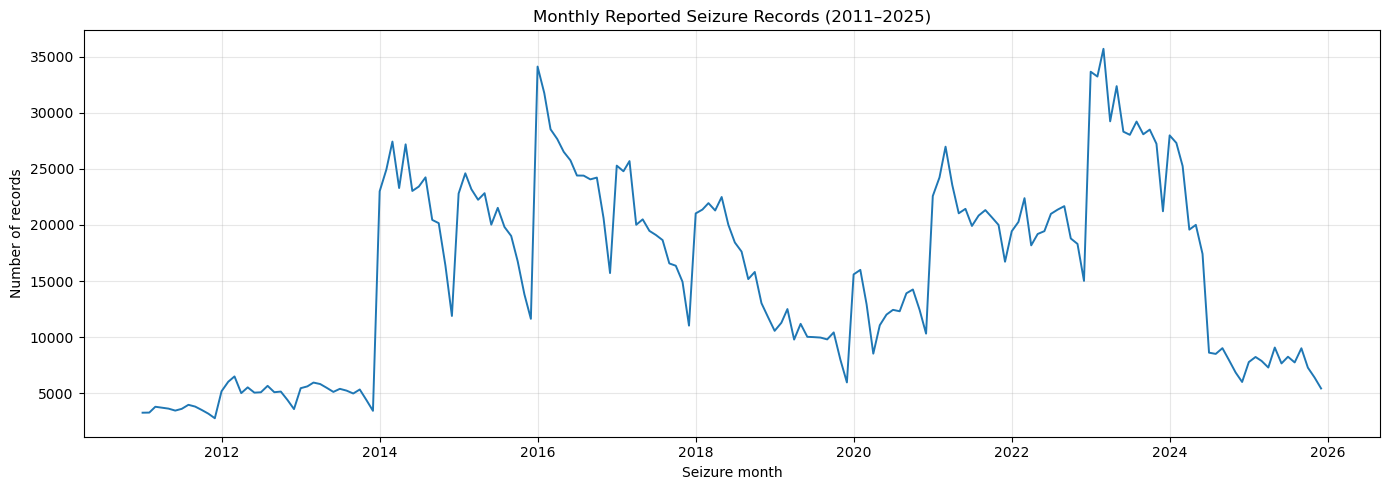

In [21]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["total_records"], linewidth=1.4)
plt.title("Monthly Reported Seizure Records (2011–2025)")
plt.xlabel("Seizure month")
plt.ylabel("Number of records")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "forecasting_monthly_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Decompose trend and seasonality

In [9]:
from statsmodels.tsa.seasonal import STL

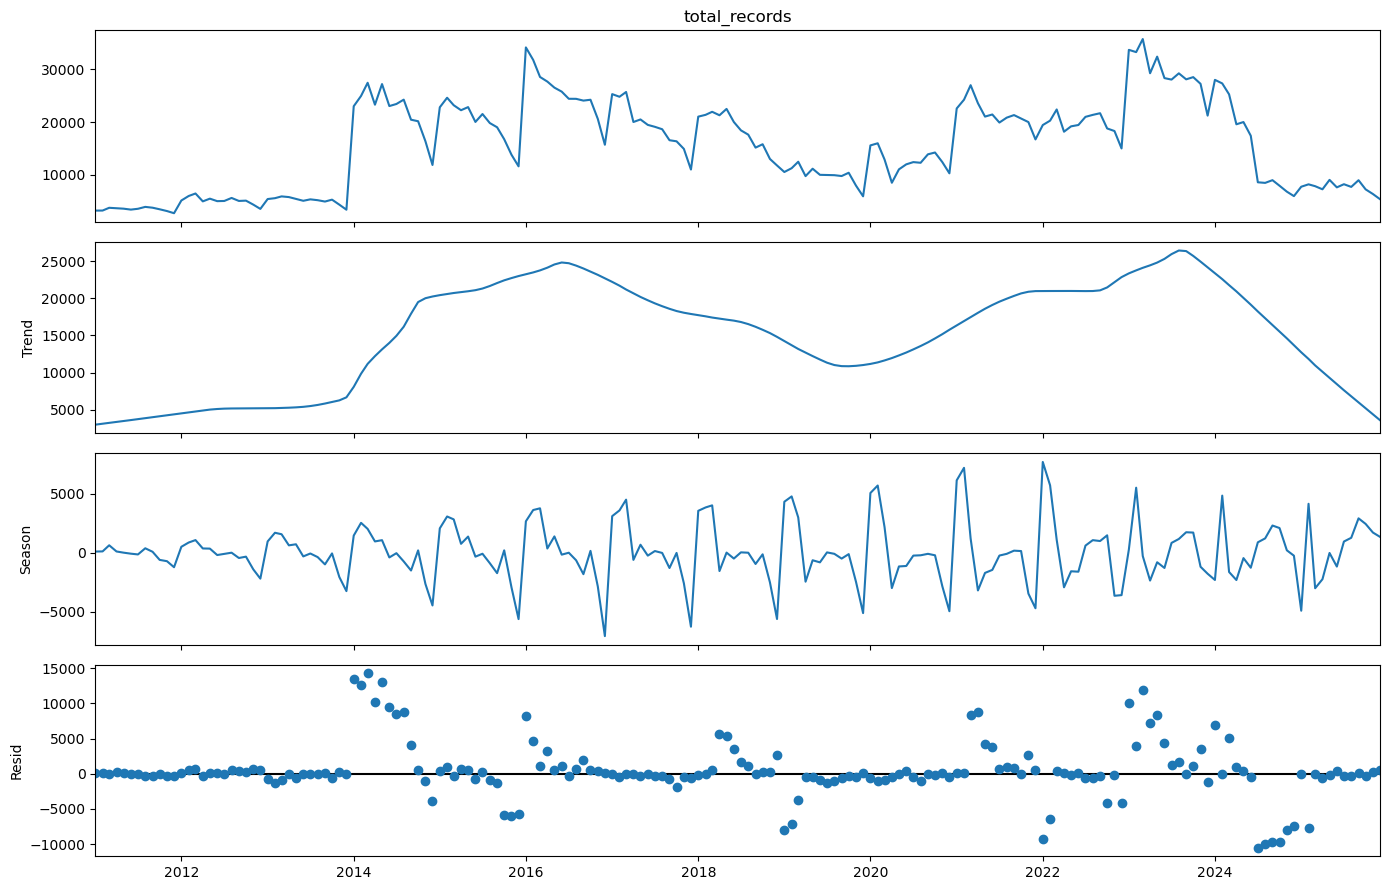

In [25]:
# STL is robust to some outlying observations and allows a seasonal
# period of 12 months.
stl = STL(df["total_records"], period=12, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "forecasting_stl_decomposition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Establish forecasting baselines

In [13]:
# Use the last 24 months as a chronological holdout.
HOLDOUT_MONTHS = 24
train_end = len(df) - HOLDOUT_MONTHS

if train_end <= 12:
    raise ValueError("Not enough observations for the chosen holdout.")

train = df.iloc[:train_end].copy()
test = df.iloc[train_end:].copy()
test_start = test.index.min()

# Naive and seasonal-naive predictions use observed historical values.
# This is rolling one-step-ahead evaluation.
naive_pred = pd.Series(
    [df.loc[d - pd.DateOffset(months=1), "total_records"] for d in test.index],
    index=test.index,
    name="Naive"
)
seasonal_pred = pd.Series(
    [df.loc[d - pd.DateOffset(years=1), "total_records"] for d in test.index],
    index=test.index,
    name="Seasonal Naive"
)

def evaluate_forecast(y_true, y_pred, model_name):
    """Return common regression metrics for a forecast."""
    y_pred = np.asarray(y_pred)
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }

baseline_results = pd.DataFrame([
    evaluate_forecast(test["total_records"], naive_pred, "Naive"),
    evaluate_forecast(test["total_records"], seasonal_pred, "Seasonal Naive")
])

display(baseline_results.round(2))

,Model,MAE,RMSE
0,Naive,1790.25,2787.37
1,Seasonal Naive,10959.38,13274.65


## 6. Build XGBoost forecasting features

In [14]:
data = df.copy()

# Calendar features
data["month"] = data.index.month
data["year"] = data.index.year
data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

# Lag features: historical values available at the forecast origin.
for lag in [1, 2, 3, 6, 12]:
    data[f"lag_{lag}"] = data["total_records"].shift(lag)

# Shift rolling windows by one month to avoid using the target month.
data["rolling_mean_3"] = (
    data["total_records"].shift(1).rolling(3).mean()
)
data["rolling_mean_12"] = (
    data["total_records"].shift(1).rolling(12).mean()
)

data = data.dropna()

feature_columns = [c for c in data.columns if c != "total_records"]
X = data[feature_columns]
y = data["total_records"]

X_train = X.loc[X.index < test_start]
y_train = y.loc[y.index < test_start]
X_test = X.loc[X.index >= test_start]
y_test = y.loc[y.index >= test_start]

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Test period:", X_test.index.min(), "to", X_test.index.max())

Training observations: 144
Test observations: 24
Test period: 2024-01-01 00:00:00 to 2025-12-01 00:00:00


## 7. Train and evaluate XGBoost

In [15]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
xgb_pred = pd.Series(
    xgb_model.predict(X_test),
    index=X_test.index,
    name="XGBoost"
)

xgb_results = pd.DataFrame([
    evaluate_forecast(y_test, xgb_pred, "XGBoost")
])

results = pd.concat(
    [baseline_results, xgb_results],
    ignore_index=True
).sort_values("MAE")

display(results.round(2))

,Model,MAE,RMSE
0,Naive,1790.25,2787.37
2,XGBoost,6244.21,6854.57
1,Seasonal Naive,10959.38,13274.65


## 8. Compare predictions

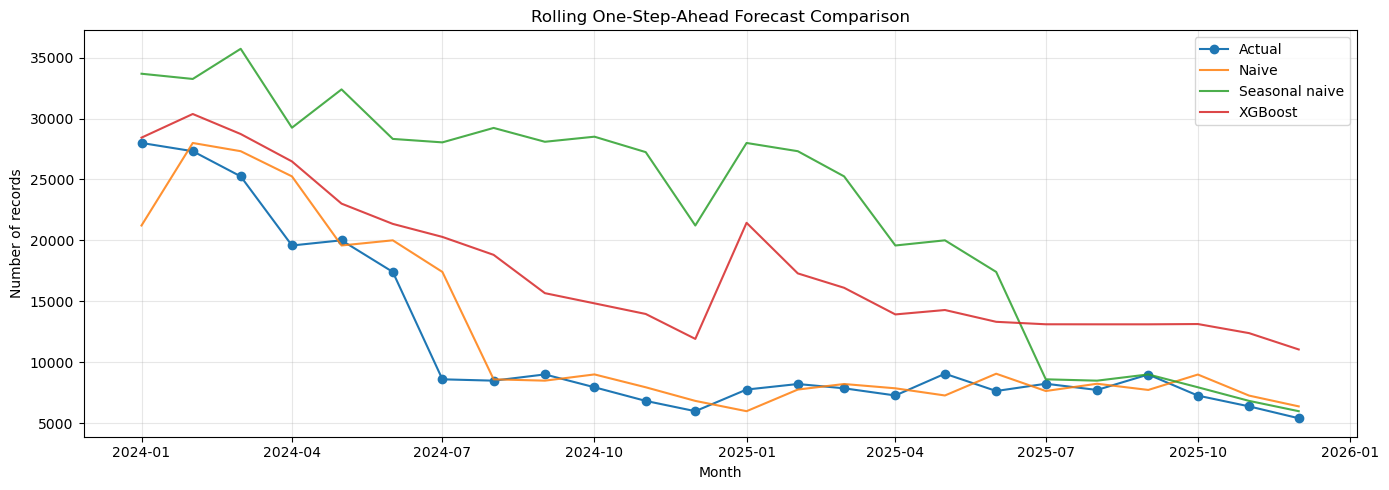

In [23]:
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test, label="Actual", marker="o", linewidth=1.5)
plt.plot(naive_pred.index, naive_pred, label="Naive", alpha=0.85)
plt.plot(seasonal_pred.index, seasonal_pred, label="Seasonal naive", alpha=0.85)
plt.plot(xgb_pred.index, xgb_pred, label="XGBoost", alpha=0.85)

plt.title("Rolling One-Step-Ahead Forecast Comparison")
plt.xlabel("Month")
plt.ylabel("Number of records")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "forecasting_holdout_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Time-series cross-validation

In [17]:
# Expanding-window cross-validation.
# Each fold evaluates 12 consecutive months. The lag features for a
# test month can use observed values from earlier months, so this is
# rolling one-step-ahead validation rather than a multi-step forecast.

tscv = TimeSeriesSplit(n_splits=5, test_size=12)
cv_rows = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    model = XGBRegressor(
        n_estimators=300,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)

    # Baselines use the actual preceding month / same month previous year.
    naive = [
        df.loc[d - pd.DateOffset(months=1), "total_records"]
        for d in y_te.index
    ]
    seasonal = [
        df.loc[d - pd.DateOffset(years=1), "total_records"]
        for d in y_te.index
    ]

    for model_name, predictions in [
        ("Naive", naive),
        ("Seasonal Naive", seasonal),
        ("XGBoost", pred)
    ]:
        cv_rows.append({
            "fold": fold,
            "period_start": y_te.index.min(),
            "period_end": y_te.index.max(),
            "model": model_name,
            "MAE": mean_absolute_error(y_te, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_te, predictions))
        })

cv_results = pd.DataFrame(cv_rows)

display(
    cv_results.groupby("model")[["MAE", "RMSE"]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

,MAE,RMSE
model,,
Naive,2318.62,3454.17
XGBoost,3482.65,4100.47
Seasonal Naive,8645.03,9748.18


## 10. Feature importance

,feature,importance
9,rolling_mean_3,0.507568
4,lag_1,0.181052
5,lag_2,0.087976
0,month,0.054994
1,year,0.046232
10,rolling_mean_12,0.037426
8,lag_12,0.031043
7,lag_6,0.019336
2,month_sin,0.018813
6,lag_3,0.009055


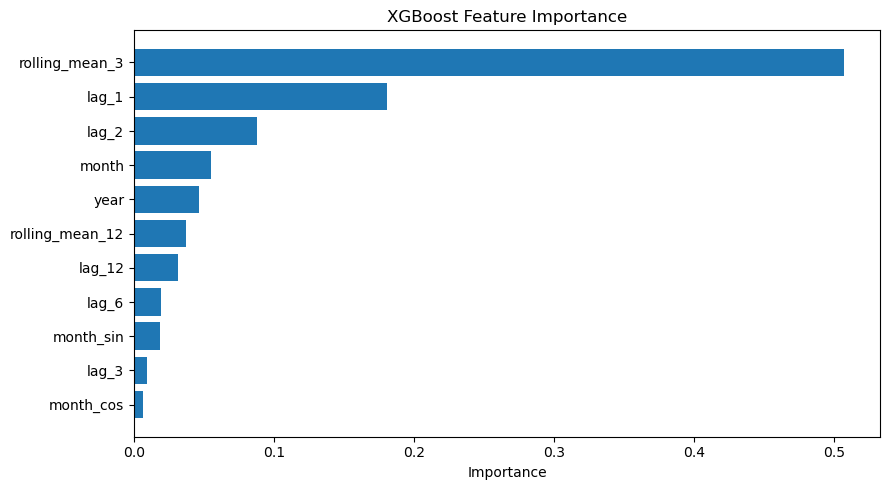

In [24]:
importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 5))
plt.barh(
    importance["feature"].iloc[::-1],
    importance["importance"].iloc[::-1]
)
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "forecasting_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Save outputs

In [19]:
# Save the monthly series, holdout predictions, metrics, and CV results.
monthly_output = df.copy()
monthly_output.to_csv(RESULTS_DIR / "forecasting_monthly_series.csv")

predictions_output = pd.DataFrame({
    "actual": y_test,
    "naive": naive_pred,
    "seasonal_naive": seasonal_pred,
    "xgboost": xgb_pred
})
predictions_output.to_csv(RESULTS_DIR / "forecasting_holdout_predictions.csv")

results.to_csv(RESULTS_DIR / "forecasting_test_metrics.csv", index=False)
cv_results.to_csv(RESULTS_DIR / "forecasting_cv_results.csv", index=False)
importance.to_csv(RESULTS_DIR / "forecasting_feature_importance.csv", index=False)

print("Forecasting outputs saved to:", RESULTS_DIR)

Forecasting outputs saved to: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\results


## Conclusions

Update this section after running the notebook. Report:
- the best-performing model on the final holdout;
- average MAE and RMSE across the five cross-validation folds;
- whether XGBoost improves on the naive baselines;
- the limits of rolling one-step-ahead evaluation.

Do not interpret forecasts as predictions of actual trafficking activity.
The target is the number of records appearing in the IDS dataset.

In [20]:
con.close()
print('DuckDB connection closed.')

DuckDB connection closed.
